 Title : Analysing the Association of Age and Sex with Diabetes Occurrence: An Exploratory Data Analysis Using the CDC Diabetes Health Indicators Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
%pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
cdc_diabetes = fetch_ucirepo(id=891)
X = cdc_diabetes.data.features
y = cdc_diabetes.data.targets
df = pd.concat([X, y], axis=1)
print("Dataset shape:", df.shape)


Dataset shape: (253680, 22)


In [ ]:
df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [ ]:
df.tail()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
253675,1,1,1,45,0,0,0,0,1,1,...,0,3,0,5,0,1,5,6,7,0
253676,1,1,1,18,0,0,0,0,0,0,...,0,4,0,0,1,0,11,2,4,1
253677,0,0,1,28,0,0,0,1,1,0,...,0,1,0,0,0,0,2,5,2,0
253678,1,0,1,23,0,0,0,0,1,1,...,0,3,0,0,0,1,7,5,1,0
253679,1,1,1,25,0,0,1,1,1,0,...,0,2,0,0,0,0,9,6,2,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                253680 non-null  int64
 1   HighChol              253680 non-null  int64
 2   CholCheck             253680 non-null  int64
 3   BMI                   253680 non-null  int64
 4   Smoker                253680 non-null  int64
 5   Stroke                253680 non-null  int64
 6   HeartDiseaseorAttack  253680 non-null  int64
 7   PhysActivity          253680 non-null  int64
 8   Fruits                253680 non-null  int64
 9   Veggies               253680 non-null  int64
 10  HvyAlcoholConsump     253680 non-null  int64
 11  AnyHealthcare         253680 non-null  int64
 12  NoDocbcCost           253680 non-null  int64
 13  GenHlth               253680 non-null  int64
 14  MentHlth              253680 non-null  int64
 15  PhysHlth              253680 non-n

In [ ]:
df.isnull().sum()

,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0
Veggies,0


In [ ]:
df.duplicated().sum()

np.int64(24206)

In [ ]:
df.nunique()

,0
HighBP,2
HighChol,2
CholCheck,2
BMI,84
Smoker,2
Stroke,2
HeartDiseaseorAttack,2
PhysActivity,2
Fruits,2
Veggies,2


In [ ]:
df['Diabetes_binary'].value_counts()

,count
Diabetes_binary,
0,218334
1,35346


In [ ]:
df['Diabetes_binary'].value_counts(normalize=True) * 100

,proportion
Diabetes_binary,
0,86.066698
1,13.933302


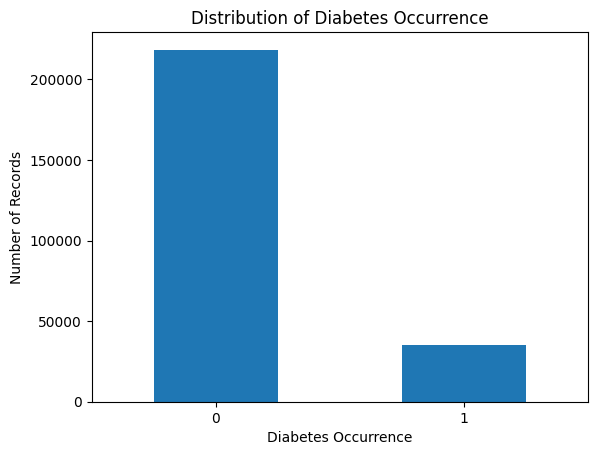

In [ ]:
df['Diabetes_binary'].value_counts().plot(kind='bar')
plt.xlabel('Diabetes Occurrence')
plt.ylabel('Number of Records')
plt.title('Distribution of Diabetes Occurrence')
plt.xticks(rotation=0)
plt.show()

The dataset contains more records in category 0 (86.07%) than in category 1 (13.93%), indicating an unequal distribution between the two target categories.

In [ ]:
df.groupby('Age')['Diabetes_binary'].mean() * 100

,Diabetes_binary
Age,
1,1.368421
2,1.842590
3,2.822979
4,4.528684
5,6.504920
6,8.789545
7,11.735198
8,13.826544
9,17.245217


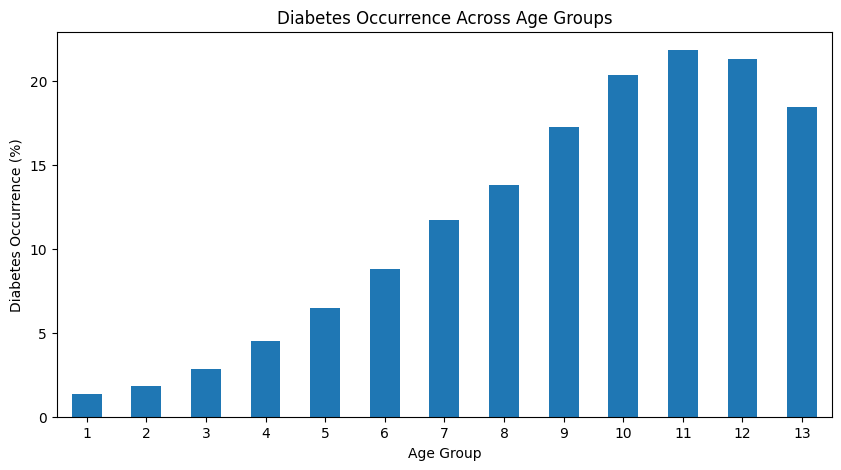

In [ ]:
(df.groupby('Age')['Diabetes_binary'].mean() * 100).plot(
    kind='bar',
    figsize=(10, 5)
)
plt.xlabel('Age Group')
plt.ylabel('Diabetes Occurrence (%)')
plt.title('Diabetes Occurrence Across Age Groups')
plt.xticks(rotation=0)
plt.show()

The percentage of records in category 1 increases across most age codes, reaches its highest value at age code 11, and decreases in age codes 12 and 13. This indicates a variation in diabetes occurrence across age groups in the dataset.

In [ ]:
df.groupby('Sex')['Diabetes_binary'].mean() * 100

,Diabetes_binary
Sex,
0,12.967867
1,15.160332


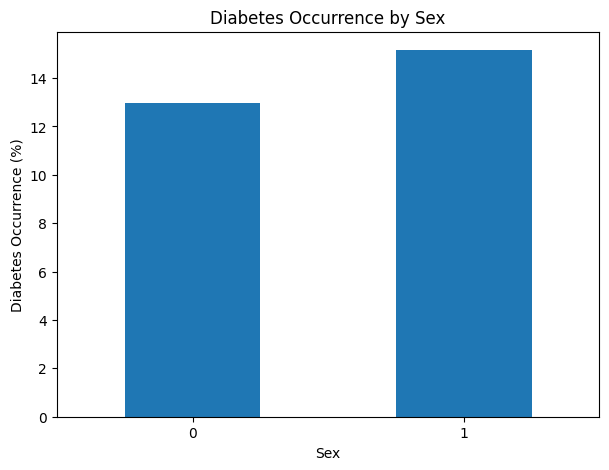

In [ ]:
(df.groupby('Sex')['Diabetes_binary'].mean() * 100).plot(
    kind='bar',
    figsize=(7, 5)
)
plt.xlabel('Sex')
plt.ylabel('Diabetes Occurrence (%)')
plt.title('Diabetes Occurrence by Sex')
plt.xticks(rotation=0)
plt.show()

 The percentage of records in target category 1 is higher in sex category 1 (15.16%) than in sex category 0 (12.97%). This shows a difference in diabetes occurrence between the two sex categories in the dataset.

In [ ]:
df['BMI'].describe()

,BMI
count,253680.000000
mean,28.382364
std,6.608694
min,12.000000
25%,24.000000
50%,27.000000
75%,31.000000
max,98.000000


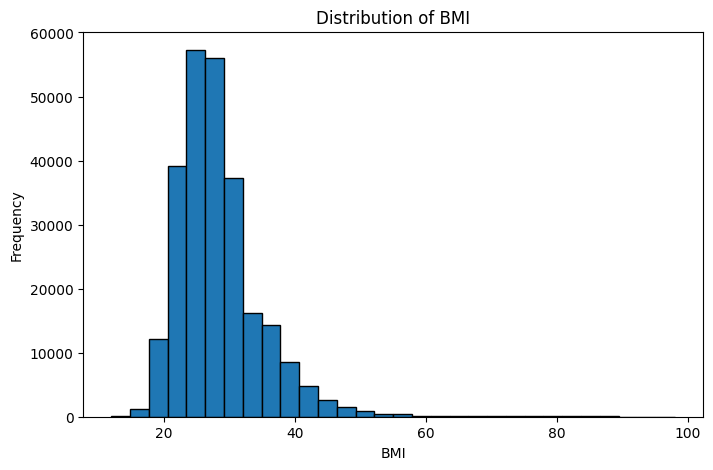

In [ ]:
df['BMI'].plot(kind='hist', bins=30, figsize=(8, 5), edgecolor='black')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.title('Distribution of BMI')
plt.show()

The mean BMI is 28.38, while the median is 27. The maximum recorded BMI is 98. The histogram helps examine the distribution and spread of BMI values in the dataset.

In [ ]:
df['BMI_Category'] = pd.cut(
    df['BMI'],
    bins=[0, 18.5, 25, 30, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'],
    right=False
)
df['BMI_Category'].value_counts()

,count
BMI_Category,
Overweight,93749
Obese,87851
Normal,68953
Underweight,3127


In [ ]:
df.groupby('BMI_Category', observed=False)['Diabetes_binary'].mean() * 100

,Diabetes_binary
BMI_Category,
Underweight,5.404541
Normal,5.696634
Overweight,11.404922
Obese,23.399847


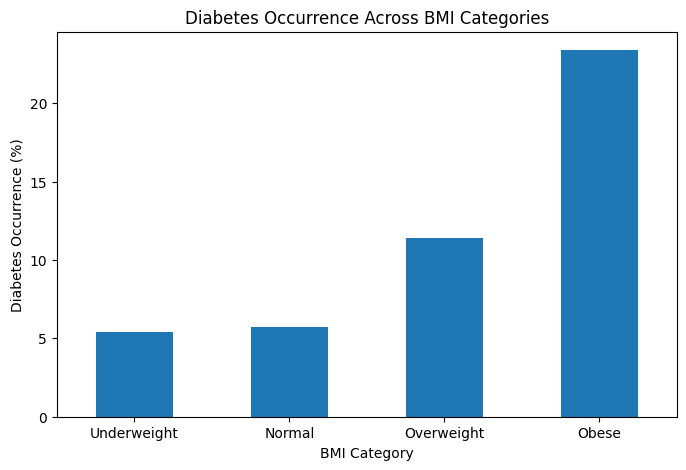

In [ ]:
(df.groupby('BMI_Category', observed=False)['Diabetes_binary'].mean() * 100).plot(
    kind='bar',
    figsize=(8, 5)
)
plt.xlabel('BMI Category')
plt.ylabel('Diabetes Occurrence (%)')
plt.title('Diabetes Occurrence Across BMI Categories')
plt.xticks(rotation=0)
plt.show()

The percentage of records in target category 1 is highest in the obese category (23.40%), followed by overweight (11.40%), normal (5.70%), and underweight (5.40%). This shows a variation in diabetes occurrence across BMI categories in the dataset.

In [ ]:
df.groupby('HighBP')['Diabetes_binary'].mean() * 100

,Diabetes_binary
HighBP,
0,6.035167
1,24.445690


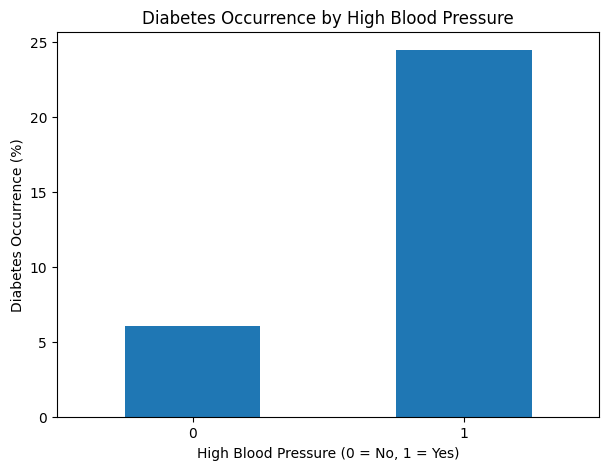

In [ ]:
(df.groupby('HighBP')['Diabetes_binary'].mean() * 100).plot(
    kind='bar',
    figsize=(7, 5)
)
plt.xlabel('High Blood Pressure (0 = No, 1 = Yes)')
plt.ylabel('Diabetes Occurrence (%)')
plt.title('Diabetes Occurrence by High Blood Pressure')
plt.xticks(rotation=0)
plt.show()

The percentage of records in target category 1 is higher among records with high blood pressure (24.45%) than among those without high blood pressure (6.04%). This shows an association between high blood pressure status and diabetes occurrence in the dataset.

In [ ]:
df.groupby('HighChol')['Diabetes_binary'].mean() * 100

,Diabetes_binary
HighChol,
0,7.981436
1,22.014853


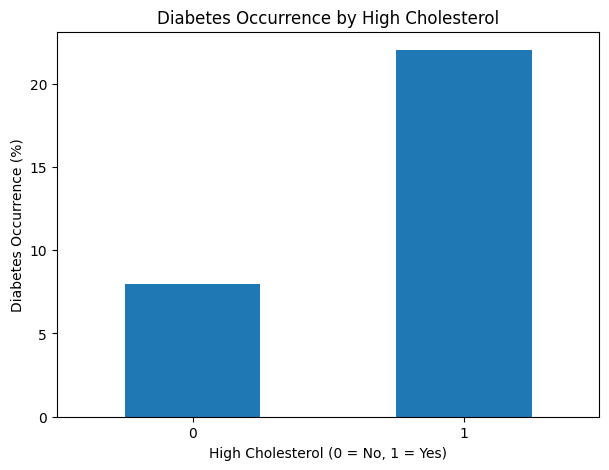

In [ ]:
(df.groupby('HighChol')['Diabetes_binary'].mean() * 100).plot(
    kind='bar',
    figsize=(7, 5)
)
plt.xlabel('High Cholesterol (0 = No, 1 = Yes)')
plt.ylabel('Diabetes Occurrence (%)')
plt.title('Diabetes Occurrence by High Cholesterol')
plt.xticks(rotation=0)
plt.show()

The percentage of records in target category 1 is higher among records with high cholesterol (22.01%) than among those without high cholesterol (7.98%). This shows a difference in diabetes occurrence between the two cholesterol categories in the dataset.

In [ ]:
df.groupby(['Sex', 'Diabetes_binary']).size()

Sex  Diabetes_binary
0    0                  123563
     1                   18411
1    0                   94771
     1                   16935
dtype: int64

In [ ]:
from scipy.stats import chi2_contingency

sex_table = df.groupby(['Sex', 'Diabetes_binary']).size().unstack()

chi2, p, dof, expected = chi2_contingency(sex_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 250.4136677541282
P-value: 2.1098747365768505e-56
Degrees of freedom: 1


The Chi-square test gives a statistic of 250.41 and a p-value of 2.11 × 10⁻⁵⁶. Since the p-value is less than 0.05, the null hypothesis is rejected. This indicates a statistically significant association between sex category and diabetes occurrence in the dataset.

In [ ]:
n = sex_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print("Cramer's V:", cramers_v)

Cramer's V: 0.03141853279120468


Cramer’s V is approximately 0.0314, indicating a very weak association between sex category and diabetes occurrence in the dataset, despite the statistically significant Chi-square test result.

In [ ]:
age_table = df.groupby(['Age', 'Diabetes_binary']).size().unstack()

chi2, p, dof, expected = chi2_contingency(age_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 8795.050613599169
P-value: 0.0
Degrees of freedom: 12


The Chi-square statistic is 8795.05 with 12 degrees of freedom. The p-value is extremely small (p < 0.001). Therefore, the null hypothesis is rejected, indicating a statistically significant association between age group and diabetes occurrence in the dataset.

In [ ]:
n = age_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / (n * min(age_table.shape[0] - 1, age_table.shape[1] - 1)))

print("Cramer's V:", cramers_v)

Cramer's V: 0.1861984481259515


Cramer’s V is approximately 0.1862, indicating a weak association between age group and diabetes occurrence in the dataset. The Chi-square test shows that this association is statistically significant.

In [ ]:
bp_table = df.groupby(['HighBP', 'Diabetes_binary']).size().unstack()

chi2, p, dof, expected = chi2_contingency(bp_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 17562.446089970756
P-value: 0.0
Degrees of freedom: 1


The Chi-square statistic is 17562.45 with 1 degree of freedom, and the p-value is less than 0.001. Therefore, the null hypothesis is rejected, indicating a statistically significant association between high blood pressure status and diabetes occurrence in the dataset.

In [ ]:
n = bp_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print("Cramer's V:", cramers_v)

Cramer's V: 0.26311729006893114


Cramer’s V is approximately 0.2631, indicating an association of moderate strength between high blood pressure status and diabetes occurrence in the dataset. The Chi-square test also indicates that this association is statistically significant.

In [ ]:
chol_table = df.groupby(['HighChol', 'Diabetes_binary']).size().unstack()

chi2, p, dof, expected = chi2_contingency(chol_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 10174.074889118883
P-value: 0.0
Degrees of freedom: 1


The Chi-square statistic is 10174.07 with 1 degree of freedom, and the p-value is less than 0.001. Therefore, the null hypothesis is rejected, indicating a statistically significant association between high cholesterol status and diabetes occurrence in the dataset.

In [ ]:
n = chol_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / n)

print("Cramer's V:", cramers_v)

Cramer's V: 0.20026467516249455


Cramer’s V is approximately 0.2003, indicating a weak association between high cholesterol status and diabetes occurrence in the dataset. The Chi-square test also indicates that this association is statistically significant.

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

if 'BMI_Category' not in df.columns:
    df['BMI_Category'] = pd.cut(
        df['BMI'],
        bins=[0, 18.5, 25, 30, float('inf')],
        labels=['Underweight', 'Normal', 'Overweight', 'Obese'],
        right=False
    )

bmi_table = df.groupby(
    ['BMI_Category', 'Diabetes_binary'],
    observed=False
).size().unstack()

chi2, p, dof, expected = chi2_contingency(bmi_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 11155.445005858777
P-value: 0.0
Degrees of freedom: 3


The Chi-square test shows a statistically significant association between BMI category and diabetes occurrence (p < 0.001). Therefore, the null hypothesis of no association is rejected. However, this result does not establish a cause-and-effect relationship.

In [ ]:
n = bmi_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(bmi_table.shape[0] - 1, bmi_table.shape[1] - 1))
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.2097009197417466


In [ ]:
results = pd.DataFrame({
    'Variable': ['Sex', 'Age Group', 'High Blood Pressure',
                 'High Cholesterol', 'BMI Category'],
    'Chi-square': [250.4137, 8795.0506, 17562.4461,
                   10174.0749, 11155.4450],
    'Degrees of Freedom': [1, 12, 1, 1, 3],
    'P-value': ['< 0.001', '< 0.001', '< 0.001',
                '< 0.001', '< 0.001'],
    "Cramér's V": [0.0314, 0.1862, 0.2631, 0.2003, 0.2097]
})
results

,Variable,Chi-square,Degrees of Freedom,P-value,Cramér's V
0,Sex,250.4137,1,< 0.001,0.0314
1,Age Group,8795.0506,12,< 0.001,0.1862
2,High Blood Pressure,17562.4461,1,< 0.001,0.2631
3,High Cholesterol,10174.0749,1,< 0.001,0.2003
4,BMI Category,11155.4450,3,< 0.001,0.2097


 All five variables show statistically significant associations with diabetes occurrence (p < 0.001). High blood pressure has the highest Cramér’s V value (0.2631), followed by BMI category (0.2097), high cholesterol (0.2003), age group (0.1862), and sex (0.0314). The strength of association varies across the variables, with sex showing a very weak association.

In [ ]:
df[['BMI', 'MentHlth', 'PhysHlth']].describe()

,BMI,MentHlth,PhysHlth
count,253680.000000,253680.000000,253680.000000
mean,28.382364,3.184772,4.242081
std,6.608694,7.412847,8.717951
min,12.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,31.000000,2.000000,3.000000
max,98.000000,30.000000,30.000000


In [ ]:
df.to_csv('Diabetes_Analyzed.csv', index=False)

In [ ]:
from google.colab import files
files.download('Diabetes_Analyzed.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>